In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score, GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, classification_report)

RANDOM_STATE = 42
POS_LABEL = 0            # here malignant is positive

In [4]:
data = load_breast_cancer()
X = data.data                    
y = data.target                  
feature_names = data.feature_names

print("Samples:", X.shape[0], " Features:", X.shape[1])
print("Class 0 =", data.target_names[0], " | Class 1 =", data.target_names[1])
print("Malignant:", int((y==0).sum()), " Benign:", int((y==1).sum()))

df = pd.DataFrame(X, columns=feature_names); df["target"] = y
df.head()

Samples: 569  Features: 30
Class 0 = malignant  | Class 1 = benign
Malignant: 212  Benign: 357


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", len(X_train), " Test:", len(X_test))

Train: 455  Test: 114


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)


Training data shape: (455, 30)
Testing data shape: (114, 30)


In [7]:
from sklearn.svm import SVC

svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=RANDOM_STATE)

svm_rbf.fit(X_train_scaled, y_train)


SVC(probability=True, random_state=42)

In [8]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_svm = svm_rbf.predict(X_test_scaled)

print("SVM (RBF) Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, target_names=data.target_names))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

SVM (RBF) Accuracy: 0.9824561403508771

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion Matrix:
[[41  1]
 [ 1 71]]


In [9]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

kernels = ['linear', 'rbf', 'poly']
svm_kernel_results = {}

for kernel in kernels:
    model = SVC(kernel=kernel, C=1.0, gamma='scale')
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, predictions)

    svm_kernel_results[kernel] = accuracy

    print(f"{kernel.upper()} Kernel Accuracy: {accuracy:.4f}")

LINEAR Kernel Accuracy: 0.9737
RBF Kernel Accuracy: 0.9825
POLY Kernel Accuracy: 0.9123


In [10]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    SVC(),
    param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", round(grid_search.best_score_, 4))


Best Parameters: {'C': 0.1, 'gamma': 0.001, 'kernel': 'linear'}
Best Cross-Validation Accuracy: 0.9758


In [11]:

from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score
)

best_svm = grid_search.best_estimator_

y_pred_best_svm = best_svm.predict(X_test_scaled)
y_prob_best_svm = best_svm.decision_function(X_test_scaled)

print("Tuned SVM Test Accuracy:",
      round(accuracy_score(y_test, y_pred_best_svm), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_best_svm,
    target_names=data.target_names
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_best_svm))

print("\nROC-AUC:",
      round(roc_auc_score(y_test, y_prob_best_svm), 4))



Tuned SVM Test Accuracy: 0.9825

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion Matrix:
[[41  1]
 [ 1 71]]

ROC-AUC: 0.9937


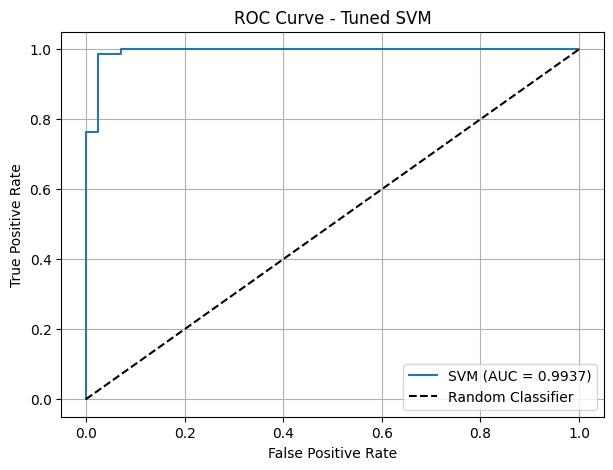

ROC-AUC Score: 0.9937


In [12]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

y_scores = best_svm.decision_function(X_test_scaled)

fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc_score = roc_auc_score(y_test, y_scores)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'SVM (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned SVM')
plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC Score:", round(auc_score, 4))



In [13]:

from sklearn.metrics import accuracy_score

train_pred = best_svm.predict(X_train_scaled)
test_pred = best_svm.predict(X_test_scaled)

print("Train Accuracy:", round(accuracy_score(y_train, train_pred) * 100, 2), "%")
print("Test Accuracy:", round(accuracy_score(y_test, test_pred) * 100, 2), "%")


Train Accuracy: 98.46 %
Test Accuracy: 98.25 %
